Matriz de confusión, costos aprendidos y decodificador de frases

In [24]:
import math
import sys
from collections import Counter, defaultdict
from functools import lru_cache
from pathlib import Path

import pandas as pd
from rapidfuzz import process
from rapidfuzz.distance import Levenshtein

# config de ruta  "corrector"
raiz = Path.cwd()
while not (raiz / "corrector").is_dir() and raiz != raiz.parent:
    raiz = raiz.parent

if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

# modulos del corrector
from corrector import Corrector, ModeloLenguaje
from corrector.confusion import VACIO, alinear, contar_pares, matriz_confusion
from corrector.datos import cargar_splits
from corrector.decodificador import decodificar
from corrector.distancia import costos_aprendidos, distancia_aprendida
from corrector.lenguaje import ModeloLenguaje
from corrector.metricas import cer_wer

In [ ]:
df = pd.read_csv(raiz / "Modelo/notebooks/data/val_predictions.csv")

In [21]:
conteo = Counter()
for real, pred in zip(df["reference"], df["prediction"]):
    for r, p in alinear(list(real), list(pred)):
        conteo[(r, p)] += 1

print(len(df), "frases |", sum(conteo.values()), "pares alineados")

340 frases | 23352 pares alineados


In [22]:
errores = [(r, p, n) for (r, p), n in conteo.items() if r != p]
for r, p, n in sorted(errores, key=lambda x: -x[2])[:20]:
    print(f"{r!r:>5} → {p!r:<5} {n}")

  ' ' → '∅'   1493
  's' → '∅'   922
  'n' → '∅'   897
  'r' → '∅'   807
  'a' → '∅'   658
  'e' → '∅'   611
  'i' → '∅'   600
  'u' → '∅'   546
  'l' → '∅'   503
  'd' → '∅'   488
  'c' → '∅'   473
  'o' → '∅'   364
  't' → '∅'   333
  'q' → '∅'   291
  'm' → '∅'   281
  'a' → 'e'   204
  'p' → '∅'   195
  'h' → '∅'   170
  'y' → '∅'   146
  ' ' → 'e'   140


In [23]:
cs = costos_aprendidos(conteo)

for w in ["herramienta", "meta", "receta", "meseta"]:
    print(f"{w:12} aprendida={distancia_aprendida('meeta', w, cs):.2f}")

herramienta  aprendida=8.62
meta         aprendida=4.08
receta       aprendida=5.85
meseta       aprendida=3.67


In [ ]:
splits = cargar_splits()
lm = ModeloLenguaje(splits["train"]["label"])
print(len(lm.vocab), "palabras en el diccionario")
def visibles(cs, tau):
    """Letras que el modelo escribe bien al menos tau de las veces."""
    return {r for (r, p), costo in cs.items() if r == p and math.exp(-costo) >= tau}

def esqueleto_umbral(palabra, vis):
    return "".join(l for l in palabra if l in vis)

for tau in [0.5, 0.3, 0.2, 0.1]:
    vis = visibles(cs, tau)
    indice = defaultdict(list)
    for w in lm.vocab:
        indice[esqueleto_umbral(w, vis)].append(w)
    tam = sorted((len(v) for v in indice.values()), reverse=True)
    print(f"tau={tau}: visibles={''.join(sorted(vis))} | {len(indice)} esqueletos | "
          f"el más grande tiene {tam[0]} palabras | vacío: {len(indice.get('', []))}")

16460 palabras en el diccionario
tau=0.5: visibles= aeo | 348 esqueletos | el más grande tiene 1068 palabras | vacío: 335
tau=0.3: visibles= aemopt | 2811 esqueletos | el más grande tiene 518 palabras | vacío: 195
tau=0.2: visibles= aefmopt | 3241 esqueletos | el más grande tiene 461 palabras | vacío: 164
tau=0.1: visibles= abefimopstu | 10244 esqueletos | el más grande tiene 92 palabras | vacío: 21


In [ ]:
def fragmentos(real, pred):
    salida, r_act, p_act = [], [], []
    for r, p in alinear(list(real), list(pred)):
        if r == " ":                                   # fin de palabra real
            if r_act:
                salida.append(("".join(r_act), "".join(p_act)))
            r_act, p_act = [], []
            continue
        if r != VACIO:
            r_act.append(r)
        if p not in (VACIO, " "):
            p_act.append(p)
    if r_act:
        salida.append(("".join(r_act), "".join(p_act)))
    return salida

pares = [fp for real, pred in zip(df["reference"], df["prediction"]) for fp in fragmentos(real, pred)]
pares = [(w, f) for w, f in pares if w in lm and f]      # palabras recuperables y pedazo no vacío
print(len(pares), "pares, ejemplos:", pares[:8])

3599 pares, ejemplos: [('hola', 'o'), ('me', 'e'), ('llamo', 'so'), ('soy', 'moo'), ('psicóloga', 'ee'), ('y', 'o'), ('mi', 'o'), ('plática', 'a')]


In [ ]:
def recall(pares, buscar):
    aciertos, tam = 0, 0
    for w, f in pares:
        cands = buscar(f)
        aciertos += w in cands
        tam += len(cands)
    return aciertos / len(pares), tam / len(pares)

# rapidfuzz contra las palabras escritas
def buscar_actual(f, n=150):
    return {c for c, _, _ in process.extract(f, lm.vocab, scorer=Levenshtein.distance, limit=n)}

r, t = recall(pares, buscar_actual)
print(f"actual (150 palabras):  recall {r:.1%} | {t:.0f} candidatas en promedio")

for tau in [0.3, 0.2, 0.1]:
    vis = visibles(cs, tau)
    indice = defaultdict(list)
    for w in lm.vocab:
        indice[esqueleto_umbral(w, vis)].append(w)
    claves = list(indice)
    for k in [5, 20]:
        def buscar(f):
            esq = esqueleto_umbral(f, vis)
            cerca = process.extract(esq, claves, scorer=Levenshtein.distance, limit=k)
            return {w for c, _, _ in cerca for w in indice[c]}
        r, t = recall(pares, buscar)
        print(f"tau={tau} K={k:>2} esqueletos: recall {r:.1%} | {t:.0f} candidatas en promedio")

actual (150 palabras):  recall 47.4% | 150 candidatas en promedio
tau=0.3 K= 5 esqueletos: recall 43.6% | 978 candidatas en promedio
tau=0.3 K=20 esqueletos: recall 64.0% | 2208 candidatas en promedio
tau=0.2 K= 5 esqueletos: recall 42.9% | 871 candidatas en promedio
tau=0.2 K=20 esqueletos: recall 62.2% | 1829 candidatas en promedio
tau=0.1 K= 5 esqueletos: recall 21.1% | 108 candidatas en promedio
tau=0.1 K=20 esqueletos: recall 40.1% | 353 candidatas en promedio


In [ ]:
frec = sorted(lm.uni, key=lm.uni.get, reverse=True)
palabras_val = [w for w, _ in pares]

for N in [1000, 3000, 6000]:
    top = set(frec[:N])
    print(f"N={N}: cobertura de val {sum(w in top for w in palabras_val) / len(palabras_val):.1%}")

N, K = 3000, 50
top = frec[:N]

@lru_cache(maxsize=None)
def ranking(f):
    return [w for _, w in sorted((distancia_aprendida(f, w, cs) + 0.05 * -lm.logp_uni(w), w) for w in top)]

for k in [20, 50, 150]:
    r_ap, _ = recall(pares, lambda f: set(ranking(f)[:k]))
    r_ac, _ = recall(pares, lambda f: buscar_actual(f, n=k))
    print(f"K={k:>3}: aprendida {r_ap:.1%} | actual {r_ac:.1%}")


N=1000: cobertura de val 82.0%
N=3000: cobertura de val 91.1%
N=6000: cobertura de val 95.5%
K= 20: aprendida 34.5% | actual 23.1%
K= 50: aprendida 44.4% | actual 29.9%
K=150: aprendida 58.8% | actual 47.4%
top 3000 + distancia aprendida, K=50: recall 40.1% | 353 candidatas


In [ ]:
df = pd.read_csv(raiz / "Modelo/notebooks/data/val_predictions.csv").fillna("")
cs = costos_aprendidos(contar_pares(df["reference"], df["prediction"]))
lm = ModeloLenguaje(cargar_splits()["train"]["label"])
top = sorted(lm.uni, key=lm.uni.get, reverse=True)[:3000]
print(len(cs), "costos |", len(top), "palabras candidatas")

1119 costos | 3000 palabras candidatas


In [ ]:
@lru_cache(maxsize=None)
def cand(f, k=50):
    puntajes = sorted((distancia_aprendida(f, w, cs) + 0.05 * -lm.logp_uni(w), w) for w in top)
    return [(w, distancia_aprendida(f, w, cs)) for _, w in puntajes[:k]]
muestra = df.head(20)
refs = muestra["reference"].tolist()
decod = [decodificar(p, lm, cand, LMAX=4) for p in muestra["prediction"]]

print("modelo solo:   CER {:.1%} | WER {:.1%}".format(*cer_wer(refs, muestra["prediction"].tolist())))
print("decodificador: CER {:.1%} | WER {:.1%}".format(*cer_wer(refs, decod)))
for r, p, d in list(zip(refs, muestra["prediction"], decod))[:5]:
    print(f"\nREAL: {r}\nPRED: {p}\nDECO: {d}")

modelo solo:   CER 67.3% | WER 101.6%
decodificador: CER 69.4% | WER 91.9%

REAL: hola me llamo giovanna gaitán soy psicóloga y mi plática se llama diseña tu vida y atrévete a vivirla
PRED: o eso e miimoo ee o o a e mometa e eime e esoetao o e moba
DECO: es lo mismo con todo lo que la primera es algo como tú

REAL: el día que cumplí treinta años entré en crisis
PRED: a eo uetetetooe eo
DECO: creo que esto solo

REAL: sí la famosa crisis de los treinta se apoderó de mí
PRED: e semota e eelo etee mi poeoim
DECO: es cómo es lo que por eso

REAL: pensé en mi proyecto de vida ese que hacemos cuando estamos en prepa o en la universidad
PRED: i me poeso e mete aa e muo oo ste moe pe pau a uomestitaa
DECO: y por eso me gustaría que nosotros tenemos pero para que se trata

REAL: y en donde nos planteamos mil objetivos que queremos lograr en nuestra vida y al que le ponemos plazos
PRED: o e o metemoo memaemosse emoa de unetevea e a e poe moato
DECO: eso me voy a esos siete de que va a por otro


In [12]:
import time
videos = sorted(df["video_id"].unique())
aprender = set(videos[: len(videos) * 3 // 5])
pa, pm = df[df["video_id"].isin(aprender)], df[~df["video_id"].isin(aprender)]
cs = costos_aprendidos(contar_pares(pa["reference"], pa["prediction"]))
cand.cache_clear()                        # la caché era con los costos viejos

muestra = pm.sample(25, random_state=0)   # 25 frases de los videos de medición
refs = muestra["reference"].tolist()
print("modelo solo: CER {:.1%} | WER {:.1%}".format(*cer_wer(refs, muestra["prediction"].tolist())))

filas = []
for beta in [-1.0, 0.0, 0.5, 1.0]:
    for lam in [0.5, 1.0, 2.0]:
        t0 = time.time()
        decod = [decodificar(p, lm, cand, lam=lam, beta=beta, LMAX=4) for p in muestra["prediction"]]
        cer, wer = cer_wer(refs, decod)
        filas.append({"beta": beta, "lam": lam, "CER": round(cer * 100, 1),
                      "WER": round(wer * 100, 1), "seg": round(time.time() - t0)})
        print(filas[-1])
pd.DataFrame(filas).sort_values("CER")

modelo solo: CER 68.5% | WER 101.2%
{'beta': -1.0, 'lam': 0.5, 'CER': 70.8, 'WER': 105.5, 'seg': 141}
{'beta': -1.0, 'lam': 1.0, 'CER': 71.6, 'WER': 97.4, 'seg': 2}
{'beta': -1.0, 'lam': 2.0, 'CER': 73.0, 'WER': 98.5, 'seg': 2}
{'beta': 0.0, 'lam': 0.5, 'CER': 71.9, 'WER': 98.3, 'seg': 2}
{'beta': 0.0, 'lam': 1.0, 'CER': 72.3, 'WER': 96.8, 'seg': 2}
{'beta': 0.0, 'lam': 2.0, 'CER': 72.7, 'WER': 97.7, 'seg': 3}
{'beta': 0.5, 'lam': 0.5, 'CER': 71.9, 'WER': 98.3, 'seg': 2}
{'beta': 0.5, 'lam': 1.0, 'CER': 72.9, 'WER': 97.4, 'seg': 2}
{'beta': 0.5, 'lam': 2.0, 'CER': 72.7, 'WER': 97.7, 'seg': 2}
{'beta': 1.0, 'lam': 0.5, 'CER': 72.5, 'WER': 98.0, 'seg': 2}
{'beta': 1.0, 'lam': 1.0, 'CER': 73.3, 'WER': 96.5, 'seg': 2}
{'beta': 1.0, 'lam': 2.0, 'CER': 72.6, 'WER': 97.7, 'seg': 2}


,beta,lam,CER,WER,seg
0,-1.0,0.5,70.8,105.5,141
1,-1.0,1.0,71.6,97.4,2
3,0.0,0.5,71.9,98.3,2
6,0.5,0.5,71.9,98.3,2
4,0.0,1.0,72.3,96.8,2
9,1.0,0.5,72.5,98.0,2
11,1.0,2.0,72.6,97.7,2
5,0.0,2.0,72.7,97.7,3
8,0.5,2.0,72.7,97.7,2
7,0.5,1.0,72.9,97.4,2


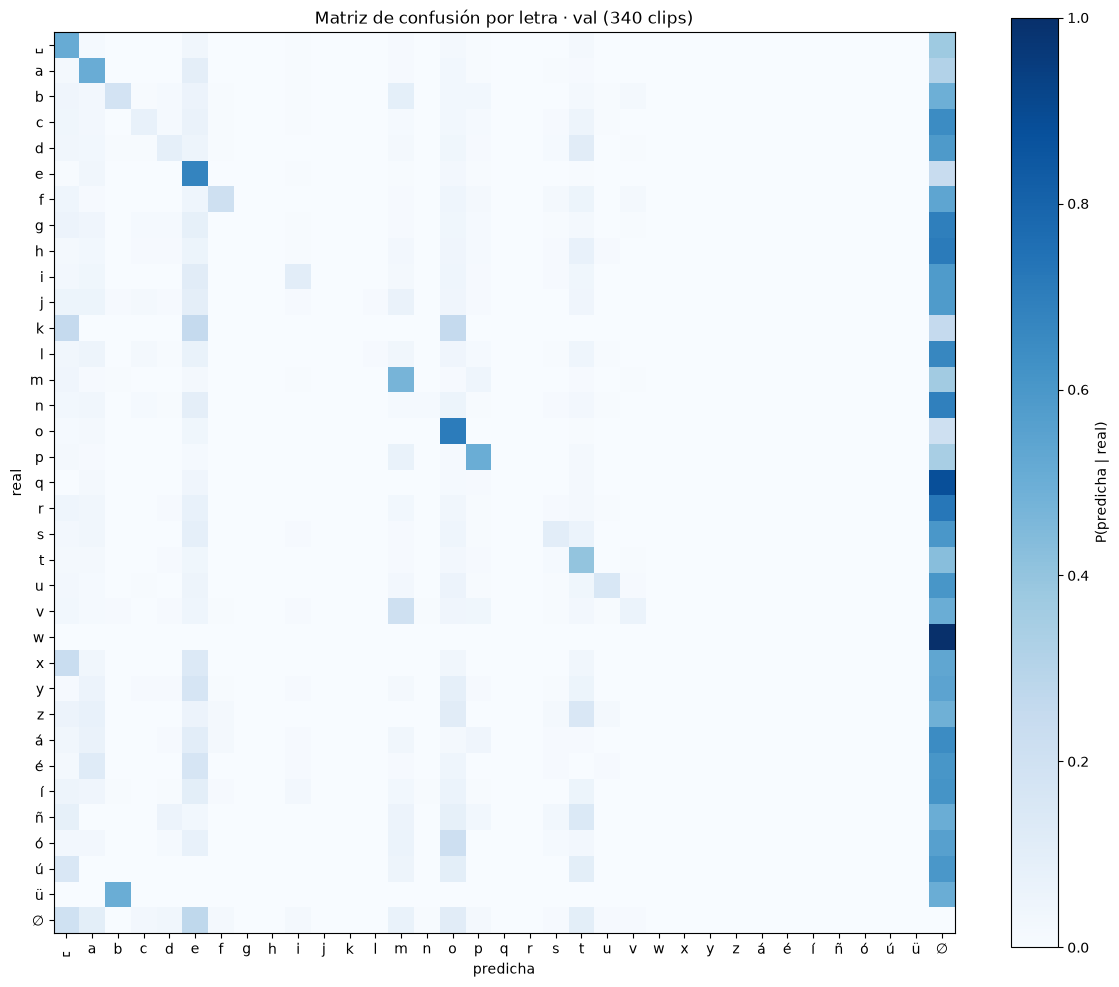

In [25]:
import matplotlib.pyplot as plt

simbolos = sorted({r for r, _ in conteo} | {p for _, p in conteo})
orden = [c for c in simbolos if c != VACIO] + [VACIO]

M = matriz_confusion(conteo, orden=orden)
if not isinstance(M, pd.DataFrame):
    M = pd.DataFrame(M, index=orden, columns=orden)

etiquetas = ["␣" if c == " " else c for c in orden]
plt.figure(figsize=(12, 10))
plt.imshow(M.values, cmap="Blues")
plt.xticks(range(len(orden)), etiquetas)
plt.yticks(range(len(orden)), etiquetas)
plt.xlabel("predicha"); plt.ylabel("real")
plt.colorbar(label="P(predicha | real)")
plt.title("Matriz de confusión por letra · val (340 clips)")
plt.tight_layout()
plt.savefig(raiz / "corrector/resultados/matriz_val.png", dpi=150)
plt.show()

In [ ]:


def fragmentos(real, pred):
    """[(palabra_real, pedazo de pred alineado con ella), ...]"""
    salida, r_act, p_act = [], [], []
    for r, p in alinear(list(real), list(pred)):
        if r == " ":
            if r_act:
                salida.append(("".join(r_act), "".join(p_act)))
            r_act, p_act = [], []
            continue
        if r != VACIO:
            r_act.append(r)
        if p not in (VACIO, " "):
            p_act.append(p)
    if r_act:
        salida.append(("".join(r_act), "".join(p_act)))
    return salida

todos = [fp for real, pred in zip(df["reference"], df["prediction"]) for fp in fragmentos(real, pred)]
vacios = Counter(w for w, f in todos if not f)
print(f"{sum(vacios.values())} de {len(todos)} palabras sin rastro ({sum(vacios.values()) / len(todos):.1%})")
print(vacios.most_common(15))

520 de 4333 palabras sin rastro (12.0%)
[('y', 77), ('que', 44), ('de', 36), ('a', 27), ('en', 26), ('un', 19), ('la', 15), ('me', 14), ('si', 14), ('no', 13), ('el', 10), ('es', 8), ('o', 7), ('sin', 7), ('ya', 6)]


In [ ]:
todos_a = [fp for real, pred in zip(pa["reference"], pa["prediction"]) for fp in fragmentos(real, pred)]
total_w = Counter(w for w, _ in todos_a)
vacio_w = Counter(w for w, f in todos_a if not f)

# costo = −log P(el modelo se comió la palabra entera); solo las que pasó al menos 3 veces
sil = sorted(((w, -math.log(vacio_w[w] / total_w[w])) for w in vacio_w if vacio_w[w] >= 3),
             key=lambda x: x[1])
print([(w, round(c, 2)) for w, c in sil])

[('sí', 0.51), ('sin', 0.51), ('ir', 0.51), ('si', 0.54), ('y', 0.6), ('hay', 0.69), ('ya', 0.92), ('un', 0.96), ('las', 1.25), ('la', 1.29), ('o', 1.34), ('qué', 1.39), ('a', 1.39), ('en', 1.47), ('que', 1.56), ('de', 1.57), ('es', 1.57), ('más', 1.61), ('mis', 1.66), ('me', 1.68), ('el', 1.69), ('no', 1.73), ('mi', 2.01), ('con', 2.08), ('yo', 2.3)]


In [15]:
lm=ModeloLenguaje(cargar_splits()["train"]["label"])
borrado = {w: distancia_aprendida("", w, cs) for w in top[:300]}
silenciosas = sorted(borrado, key=borrado.get)[:15]
print([(w, round(borrado[w], 2)) for w in silenciosas])

[('y', 0.59), ('ir', 0.84), ('un', 0.84), ('él', 0.85), ('ni', 0.92), ('sé', 0.97), ('su', 0.99), ('qué', 1.05), ('a', 1.06), ('sí', 1.06), ('si', 1.06), ('tu', 1.27), ('ha', 1.38), ('e', 1.41), ('sin', 1.43)]


In [16]:
borrado = {w: distancia_aprendida("", w, cs) for w in top[:300]}
sil = [(w, borrado[w]) for w in sorted(borrado, key=borrado.get)[:15]]

filas = []
for bono in [0.0, -1.0, -2.0, -3.0]:
    for lam in [0.5, 1.0]:
        decod = [decodificar(p, lm, cand, lam=lam, beta=1.0, LMAX=4,
                             silenciosas=sil, bono_sil=bono)
                 for p in muestra["prediction"]]
        cer, wer = cer_wer(refs, decod)
        filas.append({"bono": bono, "lam": lam, "CER": round(cer * 100, 1), "WER": round(wer * 100, 1)})
        print(filas[-1])

{'bono': 0.0, 'lam': 0.5, 'CER': 72.5, 'WER': 98.0}
{'bono': 0.0, 'lam': 1.0, 'CER': 73.3, 'WER': 96.5}
{'bono': -1.0, 'lam': 0.5, 'CER': 72.5, 'WER': 98.0}
{'bono': -1.0, 'lam': 1.0, 'CER': 73.3, 'WER': 96.5}
{'bono': -2.0, 'lam': 0.5, 'CER': 72.6, 'WER': 98.0}
{'bono': -2.0, 'lam': 1.0, 'CER': 73.4, 'WER': 97.1}
{'bono': -3.0, 'lam': 0.5, 'CER': 72.2, 'WER': 100.9}
{'bono': -3.0, 'lam': 1.0, 'CER': 73.3, 'WER': 96.8}
